# Decision trees on the wine dataset

The wine dataset has 178 wines made from three grape cultivars grown in the same region of Italy, with 13 chemical measurements for each. A decision tree learns a sequence of yes/no questions about those measurements (for example "is flavanoids ≤ 1.4?") that sorts the wines into the three classes.

In [1]:
import pandas as pd
from sklearn.datasets import load_wine

wine_data = load_wine(as_frame=True)

df = wine_data.frame
print("--- Primele 5 rânduri din dataset ---")
print(df.head().to_string())

print("\n--- Caracteristicile disponibile ---")
print(wine_data.feature_names)

--- Primele 5 rânduri din dataset ---
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  od280/od315_of_diluted_wines  proline  target
0    14.23        1.71  2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64  1.04                          3.92   1065.0       0
1    13.20        1.78  2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38  1.05                          3.40   1050.0       0
2    13.16        2.36  2.67               18.6      101.0           2.80        3.24                  0.30             2.81             5.68  1.03                          3.17   1185.0       0
3    14.37        1.95  2.50               16.8      113.0           3.85        3.49                  0.24             2.18             7.80  0.86                          3.45   14

## A shallow tree with two features

With `max_depth=2` and only alcohol and flavanoids, the whole tree fits in one picture. Each box shows its question, the Gini impurity (0 means every wine in the box belongs to the same class), how many wines reach it and the class most of them belong to.

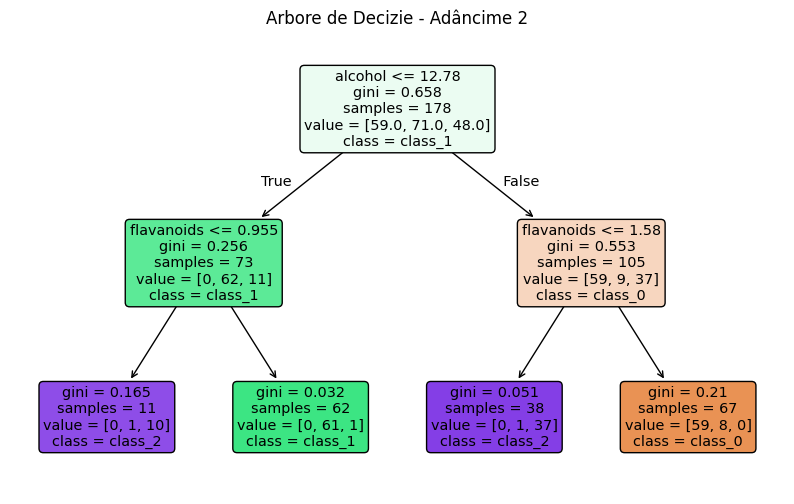

In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

X_ex2 = df[['alcohol', 'flavanoids']]
y = wine_data.target

tree_ex2 = DecisionTreeClassifier(max_depth=2, random_state=42)
tree_ex2.fit(X_ex2, y)

plt.figure(figsize=(10, 6))
plot_tree(tree_ex2,
          feature_names=['alcohol', 'flavanoids'],
          class_names=wine_data.target_names,
          filled=True,
          rounded=True)
plt.title("Arbore de Decizie - Adâncime 2")
plt.show()

## A full tree on all 13 features

30% of the wines are kept for testing. Without a depth limit the tree keeps splitting until every leaf is pure. That often overfits, but on this small, clean dataset it still classifies about 96% of the test wines correctly.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X = wine_data.data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

tree_full = DecisionTreeClassifier(max_depth=None, random_state=42)
tree_full.fit(X_train, y_train)

y_pred = tree_full.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\n--- Acuratețea modelului (max_depth=None) ---")
print(f"Acuratețe: {accuracy * 100:.2f}%")


--- Acuratețea modelului (max_depth=None) ---
Acuratețe: 96.30%


## Which features matter

Feature importance adds up how much each feature lowered the impurity across all the splits in the tree. Flavanoids and colour intensity do almost all the work. Several features score 0 because the tree never used them. That doesn't mean they carry no information, since another feature may have been just as good at the same split.

In [4]:
import numpy as np

importances = tree_full.feature_importances_

feat_imp_df = pd.DataFrame({
    'Caracteristică': wine_data.feature_names,
    'Importanță': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importanță', ascending=False)

print("\n--- Importanța caracteristicilor ---")
print(feat_imp_df.to_string(index=False))


--- Importanța caracteristicilor ---
              Caracteristică  Importanță
                  flavanoids    0.414659
             color_intensity    0.411475
                     proline    0.128900
                         ash    0.023961
                     alcohol    0.021005
                   magnesium    0.000000
           alcalinity_of_ash    0.000000
                  malic_acid    0.000000
               total_phenols    0.000000
             proanthocyanins    0.000000
        nonflavanoid_phenols    0.000000
                         hue    0.000000
od280/od315_of_diluted_wines    0.000000
